<a href="https://colab.research.google.com/github/umeshkumarsahu07/DMPM-LAB/blob/main/DMPM_08_K_MEAN_K_MEDOIDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install scikit-learn-extra


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 15.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154551 sha256=52dc103621eb97c00413a1ae28f834c32df13262681bc22cb34aa787b410adf4
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [ ]:
from sklearn_extra.cluster import KMedoids

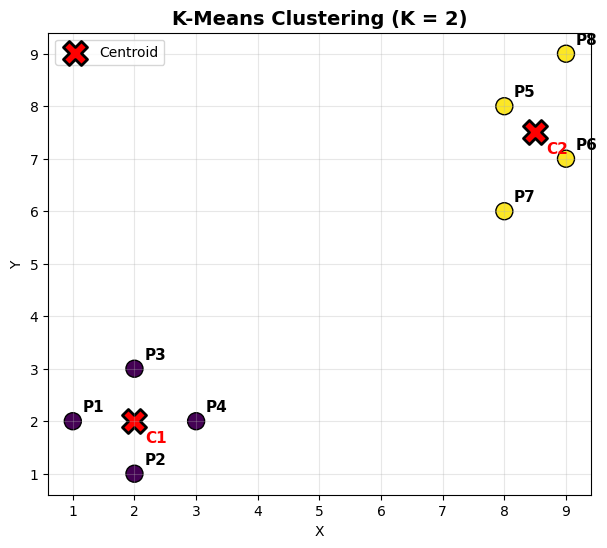

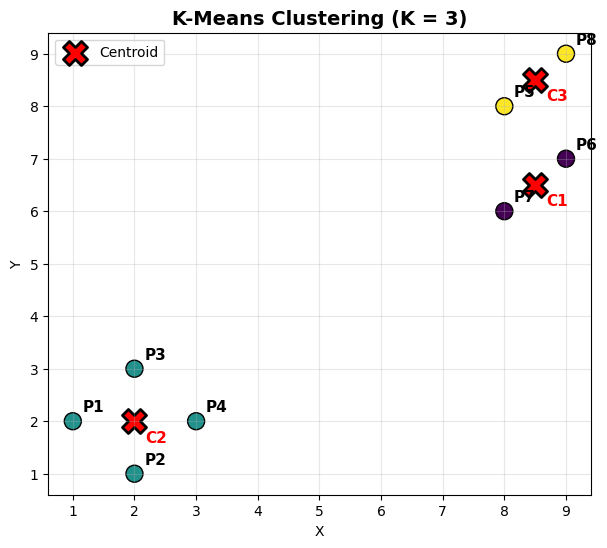

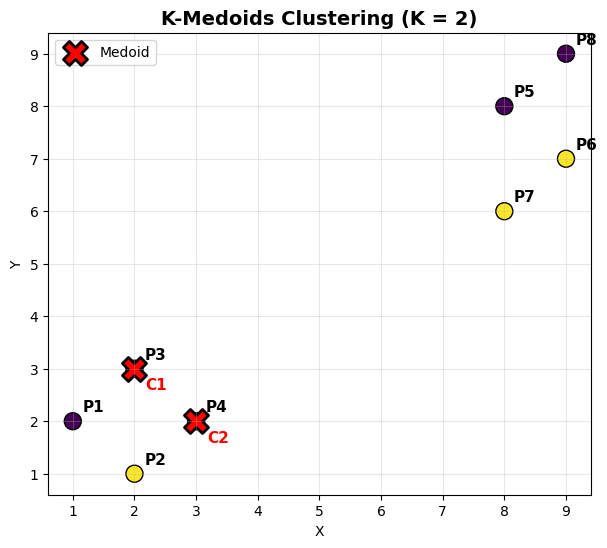

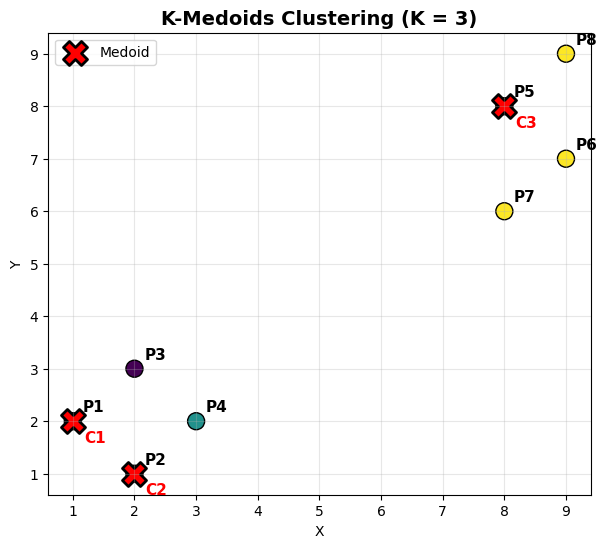

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# =====================================================
# DATASET - 8 DATA POINTS
# =====================================================

X = np.array([
    [1, 2],   # P1
    [2, 1],   # P2
    [2, 3],   # P3
    [3, 2],   # P4
    [8, 8],   # P5
    [9, 7],   # P6
    [8, 6],   # P7
    [9, 9]    # P8
])

point_names = ["P1", "P2", "P3", "P4",
               "P5", "P6", "P7", "P8"]


# =====================================================
# COMMON GRAPH FUNCTION
# =====================================================

def plot_clusters(X, labels, centers, title, medoid=False):

    plt.figure(figsize=(7, 6))

    # Plot data points
    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap="viridis",
        s=150,
        edgecolors="black"
    )

    # Add point names
    for i, name in enumerate(point_names):
        plt.annotate(
            name,
            (X[i, 0], X[i, 1]),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=11,
            fontweight="bold"
        )

    # Plot centers / medoids
    plt.scatter(
        centers[:, 0],
        centers[:, 1],
        c="red",
        marker="X",
        s=300,
        edgecolors="black",
        linewidth=2,
        label="Medoid" if medoid else "Centroid"
    )

    # Label centers
    for i, center in enumerate(centers):
        plt.annotate(
            f"C{i+1}",
            (center[0], center[1]),
            xytext=(8, -15),
            textcoords="offset points",
            fontsize=11,
            color="red",
            fontweight="bold"
        )

    plt.title(title, fontsize=14, fontweight="bold")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


# =====================================================
# K-MEANS
# =====================================================

# K = 2
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

plot_clusters(
    X,
    labels,
    kmeans.cluster_centers_,
    "K-Means Clustering (K = 2)"
)


# K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

plot_clusters(
    X,
    labels,
    kmeans.cluster_centers_,
    "K-Means Clustering (K = 3)"
)


# =====================================================
# K-MEDOIDS FUNCTION
# =====================================================

def k_medoids(X, k, max_iterations=100):

    # Select first k points as initial medoids
    medoid_indices = np.arange(k)

    for _ in range(max_iterations):

        # Calculate distance from every point to every medoid
        distances = np.zeros((len(X), k))

        for i in range(len(X)):
            for j in range(k):
                distances[i, j] = np.linalg.norm(
                    X[i] - X[medoid_indices[j]]
                )

        # Assign points to closest medoid
        labels = np.argmin(distances, axis=1)

        new_medoid_indices = medoid_indices.copy()

        # Find best medoid for each cluster
        for cluster in range(k):

            cluster_points = np.where(labels == cluster)[0]

            if len(cluster_points) == 0:
                continue

            best_medoid = cluster_points[0]
            best_cost = float("inf")

            for candidate in cluster_points:

                cost = 0

                for point in cluster_points:
                    cost += np.linalg.norm(
                        X[candidate] - X[point]
                    )

                if cost < best_cost:
                    best_cost = cost
                    best_medoid = candidate

            new_medoid_indices[cluster] = best_medoid

        # Stop if medoids don't change
        if np.array_equal(
            medoid_indices,
            new_medoid_indices
        ):
            break

        medoid_indices = new_medoid_indices

    # Final labels
    distances = np.zeros((len(X), k))

    for i in range(len(X)):
        for j in range(k):
            distances[i, j] = np.linalg.norm(
                X[i] - X[medoid_indices[j]]
            )

    labels = np.argmin(distances, axis=1)

    medoids = X[medoid_indices]

    return labels, medoids


# =====================================================
# K-MEDOIDS
# =====================================================

# K = 2
labels, medoids = k_medoids(X, 2)

plot_clusters(
    X,
    labels,
    medoids,
    "K-Medoids Clustering (K = 2)",
    medoid=True
)


# K = 3
labels, medoids = k_medoids(X, 3)

plot_clusters(
    X,
    labels,
    medoids,
    "K-Medoids Clustering (K = 3)",
    medoid=True
)
